SAMPLE EMPLOYEE DATA
   weekly_hours  overtime_hours  engagement_score  absence_days  \
0     43.108904        1.033634          1.675740             0   
1     63.275001       10.627093          2.114361             0   
2     55.619788       10.812702          1.708042             0   
3     50.953047       12.748598          1.354810             2   
4     35.460652       14.521827          1.482543             2   
5     35.459808       19.517042          2.843115             2   
6     32.032926       10.326007          1.825335             2   
7     60.316165        6.459129          2.457079             1   
8     51.039025       15.903724          3.013669             2   
9     54.782540        5.416645          3.761579             4   

   tasks_completed  
0               36  
1               35  
2               27  
3               22  
4               40  
5               22  
6               35  
7               34  
8               31  
9               34  

SUMMARY S

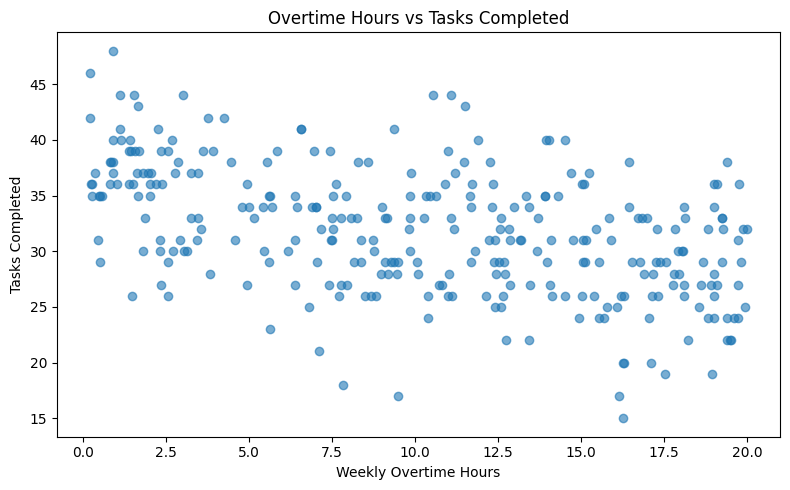

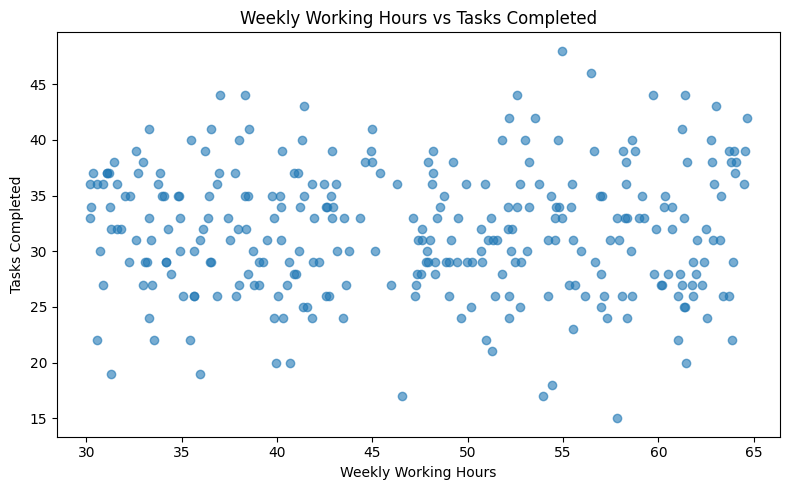

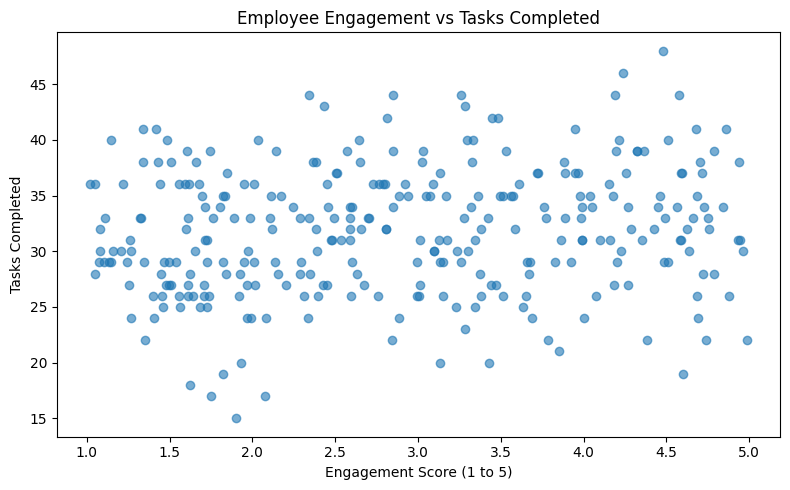


PRODUCTIVITY BY OVERTIME GROUP
                employee_count  average_tasks  average_engagement  \
overtime_group                                                      
0-5 hours                   75          36.05                2.75   
5-10 hours                  69          31.54                2.80   
10-15 hours                 71          31.75                2.96   
15+ hours                   85          28.27                3.01   

                average_absences  
overtime_group                    
0-5 hours                   1.55  
5-10 hours                  1.48  
10-15 hours                 1.56  
15+ hours                   1.48  

POTENTIAL WORKLOAD CONCERNS
workload_flag
No automatic flag                 252
Review workload and engagement     48
Name: count, dtype: int64

SAMPLE RECORDS FOR WORKLOAD REVIEW
 weekly_hours  overtime_hours  engagement_score  absence_days  tasks_completed overtime_group                  workload_flag
        50.95           12.75        

In [1]:

# PROJECT 7: EMPLOYEE PRODUCTIVITY VS WORKLOAD

# STEP 1: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)


# STEP 2: GENERATE SYNTHETIC EMPLOYEE DATA

n = 300

df = pd.DataFrame({
    "weekly_hours": np.random.uniform(30, 65, n),
    "overtime_hours": np.random.uniform(0, 20, n),
    "engagement_score": np.random.uniform(1, 5, n),
    "absence_days": np.random.poisson(1.5, n)
})

# Generate illustrative task completion values
df["tasks_completed"] = np.maximum(
    1,
    (
        35
        + 0.7 * df["engagement_score"]
        - 0.45 * df["overtime_hours"]
        - 0.25 * df["absence_days"]
        + np.random.normal(0, 5, n)
    )
).round().astype(int)

print("SAMPLE EMPLOYEE DATA")
print(df.head(10))


# STEP 3: DESCRIPTIVE STATISTICS

print("\nSUMMARY STATISTICS")
print(df.describe().round(2))


# STEP 4: CORRELATION ANALYSIS

correlations = df.corr(numeric_only=True)

print("\nCORRELATION MATRIX")
print(correlations.round(3))

print("\nCORRELATION WITH TASKS COMPLETED")
print(
    correlations["tasks_completed"]
    .sort_values(ascending=False)
    .round(3)
)


# STEP 5: OVERTIME VS PRODUCTIVITY

plt.figure(figsize=(8, 5))

plt.scatter(
    df["overtime_hours"],
    df["tasks_completed"],
    alpha=0.6
)

plt.title("Overtime Hours vs Tasks Completed")
plt.xlabel("Weekly Overtime Hours")
plt.ylabel("Tasks Completed")
plt.tight_layout()
plt.show()


# STEP 6: WORKING HOURS VS PRODUCTIVITY

plt.figure(figsize=(8, 5))

plt.scatter(
    df["weekly_hours"],
    df["tasks_completed"],
    alpha=0.6
)

plt.title("Weekly Working Hours vs Tasks Completed")
plt.xlabel("Weekly Working Hours")
plt.ylabel("Tasks Completed")
plt.tight_layout()
plt.show()


# STEP 7: ENGAGEMENT VS PRODUCTIVITY

plt.figure(figsize=(8, 5))

plt.scatter(
    df["engagement_score"],
    df["tasks_completed"],
    alpha=0.6
)

plt.title("Employee Engagement vs Tasks Completed")
plt.xlabel("Engagement Score (1 to 5)")
plt.ylabel("Tasks Completed")
plt.tight_layout()
plt.show()


# STEP 8: COMPARE EMPLOYEE GROUPS

df["overtime_group"] = pd.cut(
    df["overtime_hours"],
    bins=[-1, 5, 10, 15, 21],
    labels=[
        "0-5 hours",
        "5-10 hours",
        "10-15 hours",
        "15+ hours"
    ]
)

group_summary = df.groupby(
    "overtime_group",
    observed=False
).agg(
    employee_count=("tasks_completed", "count"),
    average_tasks=("tasks_completed", "mean"),
    average_engagement=("engagement_score", "mean"),
    average_absences=("absence_days", "mean")
).round(2)

print("\nPRODUCTIVITY BY OVERTIME GROUP")
print(group_summary)


# STEP 9: IDENTIFY POTENTIAL WORKLOAD CONCERNS

df["workload_flag"] = np.where(
    (df["overtime_hours"] > 12)
    & (df["engagement_score"] < 2.5),
    "Review workload and engagement",
    "No automatic flag"
)

print("\nPOTENTIAL WORKLOAD CONCERNS")
print(df["workload_flag"].value_counts())

print("\nSAMPLE RECORDS FOR WORKLOAD REVIEW")
print(
    df.loc[
        df["workload_flag"] == "Review workload and engagement"
    ].head(10).round(2).to_string(index=False)
)


# STEP 10: BUSINESS RECOMMENDATIONS

print("\nBUSINESS RECOMMENDATIONS")

print("1. Review repeated overtime and workload distribution.")
print("2. Investigate bottlenecks affecting task completion.")
print("3. Gather employee feedback about workload and engagement.")
print("4. Review task complexity before comparing productivity.")
print("5. Test workload improvements and measure their outcomes.")

print("\nPROJECT 7 COMPLETED SUCCESSFULLY")
print("Note: Synthetic data is used for demonstration.")
